# Importações - Bibliotecas

In [4]:
# Bibliotecas para trabalhar dados
import numpy as np
import pandas as pd

# Bibliotecas para força bruta e mensuração de tempo
import itertools
import timeit

# Bibliotecas para visualização gráfica
import matplotlib.pyplot as plt

# BD

In [5]:
import os
import kagglehub

In [6]:
tsp_path = kagglehub.dataset_download("ziya07/traveling-salesman-problem-tsplib-dataset")

In [7]:
tsp_db = pd.read_csv(os.path.join(tsp_path,"tsp_dataset.csv"))

In [8]:
num_cities = tsp_db["num_cities"].copy()
#dist_mat = tsp_db["distance_matrix"].copy()
dist_mat = tsp_db["distance_matrix"].astype(str).tolist()

In [9]:
#Tratar os dados das matrizes de distâncias
for i in range(len(dist_mat)):
  dist_mat[i] = dist_mat[i].replace("[", "")
  dist_mat[i] = dist_mat[i].replace("]", "")
  dist_mat[i] = dist_mat[i].split(",")
  dist_mat[i] = [float(x) for x in dist_mat[i]]
  dist_mat[i] = np.reshape(dist_mat[i], (num_cities[i], num_cities[i]))

Criação de caso de TSP "artificial" (de fora do banco de dados) com 11 cidades

In [10]:
coords = [
    [-1.0856306033005612, -0.6788861516220543],
    [0.9973454465835858, -0.09470896893689112],
    [0.28297849805199204, 1.4913896261242878],
    [-1.506294713918092, -0.638901996684651],
    [-0.5786002519685364, -0.44398195964606546],
    [1.651436537097151, -0.43435127561851733],
    [-2.426679243393074, 2.2059300827254558],
    [-0.42891262885617726, 2.1867860889737867],
    [1.265936258705534, 1.0040538978788771],
    [-0.8667404022651017, 0.38618639917485597],
    [0.7342185912038842, -1.2674398821105523]
]

In [11]:
#num_cities = pd.concat([num_cities, pd.Series(10), index=[len(num_cities)]])
num_cities = pd.concat(
    [num_cities, pd.Series([len(coords)], index=[len(num_cities)])]
)

In [12]:
def calculate_dist(city1, city2):
  distancex = city2[0] - city1[0]
  distancey = city2[1] - city1[1]
  return np.sqrt(distancex**2 + distancey**2)

def generate_dist_mat(coords):
  dist_mat = []
  for i in range(len(coords)):
    dist_mat.append([])
    for j in range(len(coords)):
      dist_mat[i].append(calculate_dist(coords[i], coords[j]))
  return dist_mat

In [13]:
dist_mat.append(generate_dist_mat(coords))

# Criar População

In [14]:
# Cria população de genótipos e retorna no formato de array de genótipos (permutações)
def generate_population(pop_size, n_stops):
  population = []
  population_size = pop_size
  for i in range(population_size):
    population.append(np.random.permutation(n_stops))
  return population

# Laço
    Cálculo de fitness - Erro

    Seleção

    Reprodução - Crossing Over

    Mutação

Fitness

In [15]:
#Calcula a fitness (distância total) de um genótipo

def calculate_fitness(genotype: list, dist_mat: list):
  distance = 0
  for i in range(len(genotype)-1):
    distance += dist_mat[genotype[i]][genotype[i+1]]
  return distance

In [16]:
#Faz esse de cima várias vezes
#Calcula a fitness de uma população de genótipos e ordena do melhor para o pior

def population_fitness(population, dist_mat):
  population_fitness = []
  for i in range(len(population)):
    population_fitness.append([i, calculate_fitness(population[i], dist_mat)])
  population_fitness.sort(key=lambda x: x[1], reverse=False)
  return(population_fitness)

Selection

In [17]:
#Seleciona os primeiros (melhores) genótipos e retorna eles

def select_best_elitism(population_fitness: list, population: list, survival_rate: float):
  best_fitted_genotypes = []
  population_fitness = population_fitness[:round(len(population_fitness)*survival_rate)]
  index, _ = zip(*population_fitness)
  for i in index:
    best_fitted_genotypes.append(population[i])
  return best_fitted_genotypes

In [18]:
#Seleciona os melhores através de embates aleatórios e os retorna

def select_tournament(population_fitness: list, population: list, survival_rate: float):
  survivors_amount = int(len(population_fitness)*survival_rate)
  while len(population_fitness) > survivors_amount:
    ind1 = np.random.randint(0, len(population_fitness))
    ind2 = np.random.randint(0, len(population_fitness))
    while ind1 == ind2:
      ind2 = np.random.randint(0, len(population_fitness))
    if (population_fitness[ind1][1] < population_fitness[ind2][1]):
      population_fitness.pop(ind2)
    else:
      population_fitness.pop(ind1)
  selected_genotypes = []
  for i in range(len(population_fitness)):
    selected_genotypes.append(population[population_fitness[i][0]])
  return selected_genotypes

Reproduction

In [19]:
#Reproduz os genótipos da entrada aleatoriamente e inclui junto aos pais para formar uma populacao cheia

def reproduce(parents: list, amount: int):
  offspring = parents.copy()
  while len(offspring) < amount:
    xo_point = np.random.randint(0, len(parents[0]))
    p1 = np.random.randint(0, len(parents))
    p2 = np.random.randint(0, len(parents))
    while p1 == p2:
      p2 = np.random.randint(0, len(parents))
    kid = list(parents[p1][:xo_point])
    for j in parents[p2]:
      if j in kid:
        continue
      else:
        kid.append(j)
    offspring.append(kid)
  return offspring

Mutation

In [20]:
#Gera pequenas alterações numa população de genótipos - Daria para separar em dois para manter mais coerente com as outras funções

def mutate(population, mut_prob):
  for i in range(len(population)):
    if np.random.rand() < mut_prob:
      m1 = np.random.randint(0, len(population[i]))
      m2 = np.random.randint(0, len(population[i]))
      population[i][m1], population[i][m2] = population[i][m2], population[i][m1]
  return population

Loop

In [21]:
def population_loop_elitism(pop_size = 50, db_num_cities = num_cities, db_dist_mat = dist_mat, epochs = 100, survival_rate = .5, mut_prob = .1, seed = 42):
  n = seed

  num_cities = db_num_cities[n]
  dist_mat = db_dist_mat[n]

  curr_best = [[],[]]
  best_generation_result = []
  fit_mean = []

  pop = generate_population(pop_size, num_cities)

  for i in range(epochs):
    pop_fit = population_fitness(pop, dist_mat)
    _, results = zip(*pop_fit)
    fit_mean.append(np.mean(results))
    pop_best = select_best_elitism(pop_fit, pop, survival_rate)

    if(i == 0 or pop_fit[0][1] < curr_best[1]):
      curr_best[0] = pop_best[0] # Genótipo
      curr_best[1] = pop_fit[0][1] # Valor de fitness do genótipo
    best_generation_result.append(pop_best[0])

    pop = reproduce(pop_best, pop_size)
    pop = mutate(pop, mut_prob)
  last_gen_results = results
  #print("\nPopulação final de genótipos (elitismo)\n", pd.DataFrame(pop), "\n") # Print para verificação de convergência foi removido devido à quantidade de texto
  return curr_best, best_generation_result, fit_mean, last_gen_results

In [22]:
#Loop de começo ao fim que retorna o melhor resultado obtido em formato [genótipo, r2], histórico de melhores geracionais e média do fitness
def population_loop_tournament(pop_size = 50, db_num_cities = num_cities, db_dist_mat = dist_mat, epochs = 100, survival_rate = .5, mut_prob = .1, seed = 42):
  n = seed

  num_cities = db_num_cities[n]
  dist_mat = db_dist_mat[n]

  curr_best = [[],[]]
  best_generation_result = []
  fit_mean = []

  pop = generate_population(pop_size, num_cities)

  for i in range(epochs):
    pop_fit = population_fitness(pop, dist_mat)
    _, results = zip(*pop_fit)
    fit_mean.append(np.mean(results))
    pop_best = select_tournament(pop_fit, pop, survival_rate)

    if(i == 0 or pop_fit[0][1] < curr_best[1]):
      curr_best[0] = pop_best[0] # Genótipo
      curr_best[1] = pop_fit[0][1] # Valor do fitness do genótipo
    best_generation_result.append(pop_best[0])

    pop = reproduce(pop_best, pop_size)
    pop = mutate(pop, mut_prob)
  last_gen_results = results
  #print("\nPopulação final de genótipos (torneio)\n", pd.DataFrame(pop), "\n") # Print para verificação de convergência foi removido devido à quantidade de texto
  return curr_best, best_generation_result, fit_mean, last_gen_results

In [23]:
def random_permutations_tsp(population_size, epochs, db_num_cities = num_cities, db_dist_mat = dist_mat, seed = 42, constant_correction = 1):
  n = seed

  num_cities = db_num_cities[n]
  dist_mat = db_dist_mat[n]

  best_result = ["genotype", float("inf")]

  eval_amount = population_size * epochs * constant_correction

  for i in range(eval_amount):
    genotype = np.random.permutation(num_cities)
    genotype_fitness = calculate_fitness(genotype, dist_mat)
    if genotype_fitness < best_result[1]:
      best_result[1] = genotype_fitness
      best_result[0] = genotype
  return best_result

In [24]:
def brute_force_tsp(db_num_cities = num_cities, db_dist_mat = dist_mat, seed = 42):
  n = seed

  num_cities = db_num_cities[n]
  dist_mat = db_dist_mat[n]

  best_result = ["genotype", float("inf")]

  for permutation in itertools.permutations(range(num_cities)):
    genotype_fitness = calculate_fitness(permutation, dist_mat)
    if genotype_fitness < best_result[1]:
      best_result[1] = genotype_fitness
      best_result[0] = permutation
  return best_result

# Execução dos algoritmos de TSP

Definição dos parâmetros


In [25]:
ps = 50
ep = 50
mp = .1
sr = .5
n = 2783

c = 1

#  Comparação de resultados - Primeira análise
  Dados "artificiais" com 11 cidades - Feito para viabilizar a força bruta

Análise de resultados - Mediante loops para estatística

In [26]:
loops = 5

Valores razoáveis de população e épocas

In [27]:
ps = 50
ep = 50
mp = .1
sr = .5
n = 2783

c = 1

In [28]:
print("\n\n-----------------------------------------------------------\n")
print("Primeira análise\n")

re_elitism_results = []
re_tournament_results = []
re_random_results = []
for i in range(loops):
  re_el_boa, _, _, _ = population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  re_elitism_results.append(re_el_boa[1])
  re_tor_boa, _, _, _ = population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  re_tournament_results.append(re_tor_boa[1])
  re_random_result = random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c)
  re_random_results.append(re_random_result[1])
brute_result = brute_force_tsp(seed=n)

print("\nResultados com os parâmetros dos algoritmos razoáveis (população = 50 e épocas = 50)\n")
print("Média elitismo - ", np.mean(re_elitism_results))
print("Média torneio - ", np.mean(re_tournament_results))
print("Média aleatório - ", np.mean(re_random_results))
print("Resultado bruto - ", float(brute_result[1]))



-----------------------------------------------------------

Primeira análise


Resultados com os parâmetros dos algoritmos razoáveis (população = 50 e épocas = 50)

Média elitismo -  12.63581504645279
Média torneio -  12.12849051363257
Média aleatório -  13.146163905816284
Resultado bruto -  10.936676705911916


Valores razoáveis - Análise temporal dos diferentes métodos

In [29]:
re_time_elitism = timeit.timeit(lambda: population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

re_time_tournament = timeit.timeit(lambda: population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

re_time_random = timeit.timeit(lambda: random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c), number= loops)

time_brute = timeit.timeit(lambda: brute_force_tsp(seed=n), number= loops)

print("\nTempo com os parâmetros dos algoritmos razoáveis (população = 50 e épocas = 50)\n")
print("Tempo elitismo - ", re_time_elitism)
print("Tempo torneio - ", re_time_tournament)
print("Tempo aleatório - ", re_time_random)
print("Tempo bruto - ", time_brute)


Tempo com os parâmetros dos algoritmos razoáveis (população = 50 e épocas = 50)

Tempo elitismo -  0.1055421330001991
Tempo torneio -  0.13783599799990043
Tempo aleatório -  0.08169654199991783
Tempo bruto -  247.33609621699998


Valores exagerados de população e épocas

In [30]:
ps = 500
ep = 500
mp = .1
sr = .5
n = 2783

c = 1

In [31]:
ex_elitism_results = []
ex_tournament_results = []
ex_random_results = []
for i in range(loops):
  ex_el_boa, _, _, _ = population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  ex_elitism_results.append(ex_el_boa[1])
  ex_tor_boa, _, _, _ = population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  ex_tournament_results.append(ex_tor_boa[1])
  ex_random_result = random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c)
  ex_random_results.append(ex_random_result[1])

print("\nResultados com os parâmetros dos algoritmos exagerados (população = 500 e épocas = 500)\n")
print("Média elitismo - ", np.mean(ex_elitism_results))
print("Média torneio - ", np.mean(ex_tournament_results))
print("Média aleatório - ", np.mean(ex_random_results))
print("Resultado bruto - ", float (brute_result[1]))


Resultados com os parâmetros dos algoritmos exagerados (população = 500 e épocas = 500)

Média elitismo -  11.116004034851331
Média torneio -  11.235265405343387
Média aleatório -  12.04650193752511
Resultado bruto -  10.936676705911916


Valores exagerados - Análise temporal dos diferentes métodos

In [32]:
ex_time_elitism = timeit.timeit(lambda: population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

ex_time_tournament = timeit.timeit(lambda: population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

ex_time_random = timeit.timeit(lambda: random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c), number= loops)

print("\nTempo com os parâmetros dos algoritmos exagerados (população = 500 e épocas = 500)\n")
print("Tempo elitismo - ", ex_time_elitism)
print("Tempo torneio - ", ex_time_tournament)
print("Tempo aleatório - ", ex_time_random)
print("Tempo bruto - ", time_brute)


Tempo com os parâmetros dos algoritmos exagerados (população = 500 e épocas = 500)

Tempo elitismo -  9.41018649399939
Tempo torneio -  13.098282226000265
Tempo aleatório -  7.631546806000188
Tempo bruto -  247.33609621699998


Plot de gráficos

Plot de gráficos razoáveis



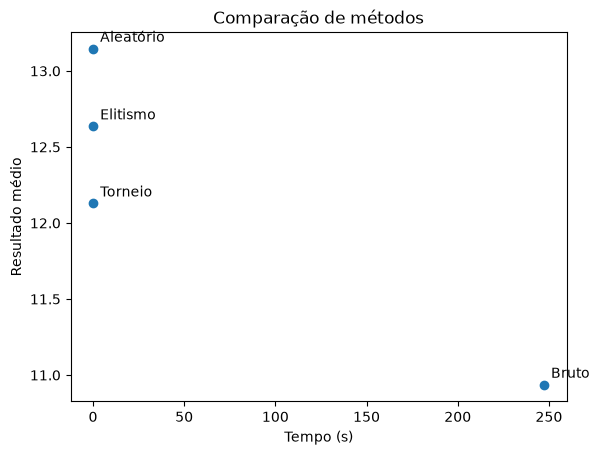

In [33]:
print("Plot de gráficos razoáveis\n")

re_time = [re_time_elitism, re_time_tournament, re_time_random, time_brute]
re_mean = [np.mean(re_elitism_results), np.mean(re_tournament_results), np.mean(re_random_results), brute_result[1]]
re_labels = ["Elitismo", "Torneio", "Aleatório", "Bruto"]

plt.scatter(re_time, re_mean)

plt.title("Comparação de métodos")
plt.xlabel("Tempo (s)")
plt.ylabel("Resultado médio")

for xi, yi, label in zip(re_time, re_mean, re_labels):
    plt.annotate(label, (xi, yi), xytext=(5, 5), textcoords="offset points")
plt.show()

Plot de gráficos exagerados



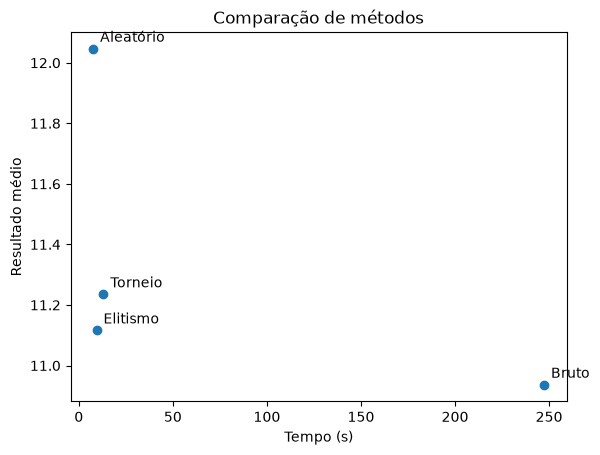

In [34]:
print("Plot de gráficos exagerados\n")

ex_time = [ex_time_elitism, ex_time_tournament, ex_time_random, time_brute]
ex_mean = [np.mean(ex_elitism_results), np.mean(ex_tournament_results), np.mean(ex_random_results), brute_result[1]]
ex_labels = ["Elitismo", "Torneio", "Aleatório", "Bruto"]

plt.scatter(ex_time, ex_mean)

plt.title("Comparação de métodos")
plt.xlabel("Tempo (s)")
plt.ylabel("Resultado médio")

for xi, yi, label in zip(ex_time, ex_mean, ex_labels):
    plt.annotate(label, (xi, yi), xytext=(5, 5), textcoords="offset points")
plt.show()

#  Comparação de resultados - Segunda análise
Comparação entre métodos heurísticos e seleção aleatória

In [35]:
ps = 500
ep = 500
mp = .1
sr = .5
n = 20

c = 1

loops = 5

In [36]:
print("\n\n-----------------------------------------------------------\n\n")
print("Segunda análise - Comparação de métodos heurísticos com aleatório\n")

elitism_results = []
tournament_results = []
random_results = []
for i in range(loops):
  el_boa, _, _, _ = population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  elitism_results.append(el_boa[1])
  tor_boa, _, _, _ = population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
  tournament_results.append(tor_boa[1])
  random_result = random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c)
  random_results.append(random_result[1])

print("\nResultados - Comparação entre métodos heurísticos e aleatórios\n")
print("Média elitismo - ", np.mean(elitism_results))
print("Média torneio - ", np.mean(tournament_results))
print("Média aleatório - ", np.mean(random_results))



-----------------------------------------------------------


Segunda análise - Comparação de métodos heurísticos com aleatório


Resultados - Comparação entre métodos heurísticos e aleatórios

Média elitismo -  432.76583655115303
Média torneio -  435.72577408304187
Média aleatório -  709.5138454204066


In [37]:
time_elitism = timeit.timeit(lambda: population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

time_tournament = timeit.timeit(lambda: population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

time_random = timeit.timeit(lambda: random_permutations_tsp(population_size=ps, epochs=ep, seed=n, constant_correction=c), number= loops)

print("\nTempo - Comparação de métodos heurísticos e aleatórios\n")
print("Tempo elitismo - ", time_elitism)
print("Tempo torneio - ", time_tournament)
print("Tempo aleatório - ", time_random)


Tempo - Comparação de métodos heurísticos e aleatórios

Tempo elitismo -  18.352954242000123
Tempo torneio -  21.36539357700076
Tempo aleatório -  16.386059618000218


Plot de gráficos

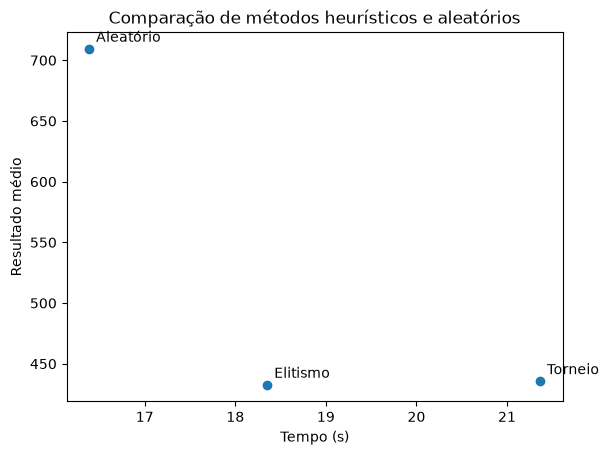

In [38]:
time = [time_elitism, time_tournament, time_random]
mean = [np.mean(elitism_results), np.mean(tournament_results), np.mean(random_results)]
labels = ["Elitismo", "Torneio", "Aleatório"]

plt.scatter(time, mean)

plt.title("Comparação de métodos heurísticos e aleatórios")
plt.xlabel("Tempo (s)")
plt.ylabel("Resultado médio")

for xi, yi, label in zip(time, mean, labels):
    plt.annotate(label, (xi, yi), xytext=(5, 5), textcoords="offset points")
plt.show()

# Comparação de resultados - Terceira análise
Comparação entre mecanismos de seleção - Elitismo e torneio

In [39]:
n = 2

c = 1

loops = 5

In [40]:
print("\n\n-----------------------------------------------------------\n\n")
print("Terceira análise - Comparação entre mecanismos de seleção\n")

print("Escala pequena - População com 50 genótipos e 50 épocas\n Escala grande - População com 500 genótipos e 500 épocas\n\n")

elitism_results = []
tournament_results = []
for i in range(loops):
  for [ps, ep, mp, sr] in ([50,50,.1,.5],
                           [500,500,.1,.5]):
    el_boa, _, _, _ = population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
    elitism_results.append(el_boa[1])
    tor_boa, _, _, _ = population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n)
    tournament_results.append(tor_boa[1])

print("\nResultados - Comparação entre métodos heurísticos\n")
print("Média elitismo - ", np.mean(elitism_results[:5]))
print("Média torneio - ", np.mean(tournament_results[:5]))
print("Média elitismo - ", np.mean(elitism_results[5:]))
print("Média torneio - ", np.mean(tournament_results[5:]))



-----------------------------------------------------------


Terceira análise - Comparação entre mecanismos de seleção

Escala pequena - População com 50 genótipos e 50 épocas
 Escala grande - População com 500 genótipos e 500 épocas



Resultados - Comparação entre métodos heurísticos

Média elitismo -  2569.353640004746
Média torneio -  2672.88851643382
Média elitismo -  2200.932904218798
Média torneio -  2342.811919097837


In [41]:
ps = 50
ep = 50
mp = .1
sr = .5

qk_time_elitism = timeit.timeit(lambda: population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)
qk_time_tournament = timeit.timeit(lambda: population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

In [42]:
ps = 500
ep = 500
mp = .1
sr = .5

lg_time_elitism = timeit.timeit(lambda: population_loop_elitism(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)
lg_time_tournament = timeit.timeit(lambda: population_loop_tournament(pop_size=ps, db_num_cities=num_cities, db_dist_mat=dist_mat, epochs=ep, survival_rate=sr, mut_prob=mp, seed=n), number= loops)

In [43]:
print("\nTempo - Comparação de métodos heurísticos\n")
print("Tempo elitismo - ", qk_time_elitism)
print("Tempo torneio - ", qk_time_tournament)
print("Tempo elitismo - ", lg_time_elitism)
print("Tempo torneio - ", lg_time_tournament)


Tempo - Comparação de métodos heurísticos

Tempo elitismo -  1.0703224710014183
Tempo torneio -  1.0998803500006034
Tempo elitismo -  101.71798343499904
Tempo torneio -  104.62730714099962


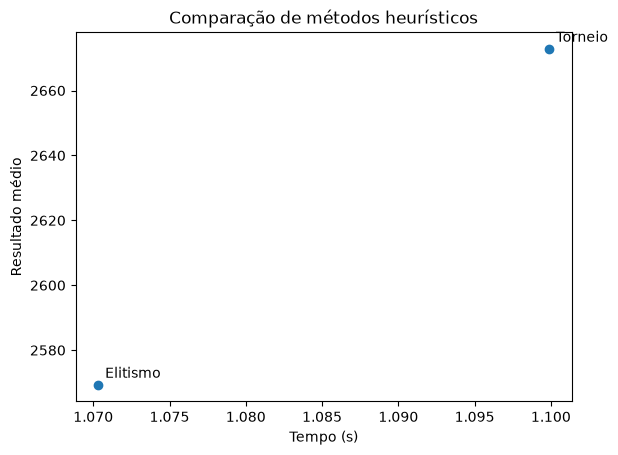

In [44]:
qk_time = [qk_time_elitism, qk_time_tournament]
qk_mean = [np.mean(elitism_results[:5]), np.mean(tournament_results[:5])]
labels = ["Elitismo", "Torneio"]

plt.scatter(qk_time, qk_mean)

plt.title("Comparação de métodos heurísticos")
plt.xlabel("Tempo (s)")
plt.ylabel("Resultado médio")

for xi, yi, label in zip(qk_time, qk_mean, labels):
    plt.annotate(label, (xi, yi), xytext=(5, 5), textcoords="offset points")
plt.show()

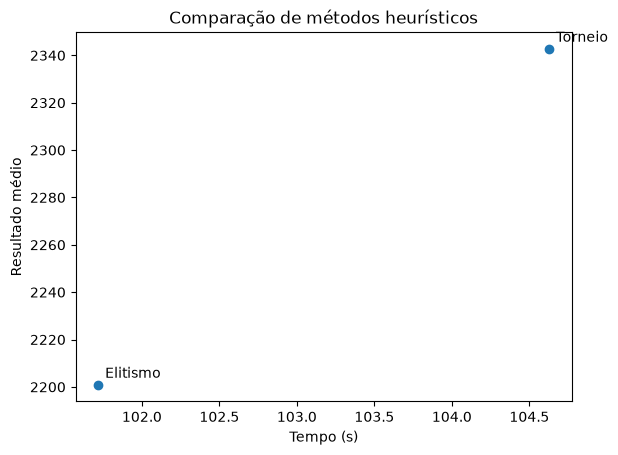

In [45]:
lg_time = [lg_time_elitism, lg_time_tournament]
lg_mean = [np.mean(elitism_results[5:]), np.mean(tournament_results[5:])]
labels = ["Elitismo", "Torneio"]

plt.scatter(lg_time, lg_mean)

plt.title("Comparação de métodos heurísticos")
plt.xlabel("Tempo (s)")
plt.ylabel("Resultado médio")

for xi, yi, label in zip(lg_time, lg_mean, labels):
    plt.annotate(label, (xi, yi), xytext=(5, 5), textcoords="offset points")
plt.show()